# Parte 5 – Segmentación

En la Parte 4 medimos, con las máscaras del radiólogo, qué **mapas** separan mejor la lesión del tejido que la rodea. Ahora usamos esos mapas para lo que realmente importa: **encontrar la lesión sin la máscara**, a partir de un solo clic del usuario dentro de ella (enfoque **semiautomático**, como propone el anteproyecto).

**Qué viene de las partes anteriores:**
- Parte 1: trabajamos sobre las imágenes **sin marcas del ecógrafo** (`artefactos.limpiar()`).
- Parte 3: el brillo y los bordes, sobre la **mediana 7 × 7**; la textura, **sin filtrar**.
- Parte 4: tres mapas que cubren las tres "dimensiones" de información que encontramos:
  - **media local** (mediana 7 × 7, ventana 15 px): el brillo, el que mejor separa (AUC 0,88);
  - **coeficiente de variación** σ/μ (sin filtrar, 31 px): la variación relativa al brillo (AUC 0,78);
  - **gradiente** promediado (sin filtrar, 31 px): la cantidad de variación (AUC 0,71).

  Y dos preguntas abiertas: **¿la textura suma algo al brillo** cuando se combinan los mapas? y **¿las ventanas de 31 px deforman el contorno?**

**Métodos** (vistos en clase), todos partiendo de la semilla:
1. **Crecimiento de regiones** (*region growing*) sobre la media local, y sobre la imagen (mediana 7 × 7) para comparar "imagen original vs. mapa", como pide el anteproyecto;
2. **k-means** sobre los tres mapas, y sobre la media local sola (para responder la pregunta de la textura);
3. **Chan-Vese** (contornos activos) sobre la media local;
4. **Otsu** sobre la media local: una referencia automática simple, sin parámetros.

**La regla más importante de esta parte:** la máscara manual se usa **solo** para (a) simular el clic del usuario y (b) evaluar. Nunca para recortar la imagen ni para guiar el método. Si un método necesita una zona de trabajo, es una **ventana fija** alrededor de la semilla, del mismo tamaño en todas las imágenes.

**Contenido**
1. La semilla y la lesión de referencia
2. Los mapas de entrada y los métodos, en un ejemplo
3. Cómo medimos: Dice e IoU
4. Elección de parámetros en un subconjunto de ajuste
5. Evaluación en el resto de las imágenes
6. Resultados: por método, por clase, comparación entre métodos, textura vs. brillo, tamaño de la lesión, ejemplos
7. Conclusiones

### Preparación

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))

%load_ext autoreload
%autoreload 2

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, mannwhitneyu
from sklearn.model_selection import train_test_split
from joblib import Parallel, delayed

from busi.datos import listar_casos, cargar_caso
from busi.config import load_config
from busi import artefactos, segmentacion

warnings.filterwarnings("ignore", category=FutureWarning)
cfg = load_config()
SEED = cfg["SEED"]
CARPETA = cfg["OUTPUT_DIR"] / "segmentacion"
CARPETA.mkdir(parents=True, exist_ok=True)

def cargar_limpio(caso):
    # Imagen sin marcas del ecógrafo (Parte 1), máscara de la lesión y máscara de las marcas reconstruidas.
    img, mascara = cargar_caso(caso)
    img, marcas = artefactos.limpiar(img)
    return img, mascara, marcas

casos = listar_casos().set_index("id")
con_lesion = casos[casos["clase"] != "normal"]
print(f"{len(con_lesion)} imágenes con lesión: {(con_lesion['clase'] == 'benign').sum()} benignas, "
      f"{(con_lesion['clase'] == 'malignant').sum()} malignas")

NOMBRES = {"rg_media": "Region growing (media local)", "rg_imagen": "Region growing (imagen)",
           "kmeans_3mapas": "k-means (3 mapas)", "kmeans_media": "k-means (media sola)",
           "chan_vese": "Chan-Vese", "otsu": "Otsu"}
COLORES = {"rg_media": "tab:blue", "rg_imagen": "tab:cyan", "kmeans_3mapas": "tab:red",
           "kmeans_media": "tab:orange", "chan_vese": "tab:green", "otsu": "tab:gray"}

647 imágenes con lesión: 437 benignas, 210 malignas


## 1. La semilla y la lesión de referencia

En uso real, el usuario haría **un clic dentro de la lesión**. Para evaluar en 647 imágenes simulamos ese clic con `segmentacion.semilla_desde_mascara()`: el punto de la máscara manual **más alejado de su borde** (el máximo de la transformada de distancia). Es un clic "bien hecho", en el centro de la lesión; un usuario real podría hacer clic más cerca del borde (lo discutimos en las limitaciones).

**Máscaras con más de una componente.** En la Parte 0 vimos 17 imágenes con varias máscaras (`_mask_1`, ...). Además, algunas máscaras de un solo archivo tienen manchas sueltas. Con **un** clic se segmenta **una** lesión, así que comparar contra la unión de todas penalizaría a cualquier método por no encontrar lesiones que nadie le marcó. Por eso la referencia es `segmentacion.lesion_principal()`: la **componente conexa de la máscara manual que contiene la semilla**.

Imágenes con más de una componente en la máscara: 34 (15 con varios archivos de máscara)


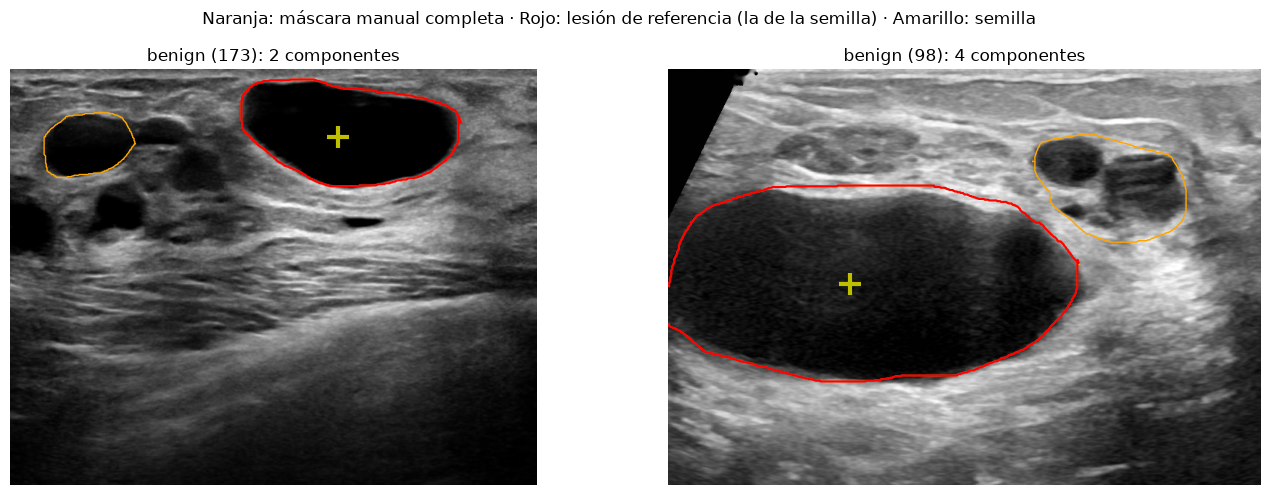

In [3]:
from skimage import measure

n_comp = {}
for id_caso, caso in con_lesion.iterrows():
    _, mascara = cargar_caso(caso)
    n_comp[id_caso] = measure.label(mascara, connectivity=2).max()
n_comp = pd.Series(n_comp)
print(f"Imágenes con más de una componente en la máscara: {(n_comp > 1).sum()} "
      f"({(con_lesion.loc[n_comp.index[n_comp > 1], 'n_mascaras'] > 1).sum()} con varios archivos de máscara)")

ejemplos_multi = ["benign (173)", "benign (98)"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, id_caso in zip(axes, ejemplos_multi):
    img, mascara, _ = cargar_limpio(casos.loc[id_caso])
    semilla = segmentacion.semilla_desde_mascara(mascara)
    principal = segmentacion.lesion_principal(mascara)
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.contour(mascara, levels=[0.5], colors="orange", linewidths=1)
    ax.contour(principal, levels=[0.5], colors="red", linewidths=1.5)
    ax.plot(semilla[1], semilla[0], "y+", markersize=16, markeredgewidth=3)
    ax.set_title(f"{id_caso}: {n_comp[id_caso]} componentes")
    ax.axis("off")
fig.suptitle("Naranja: máscara manual completa · Rojo: lesión de referencia (la de la semilla) · Amarillo: semilla")
plt.tight_layout()
plt.show()

**Qué vemos:** 34 de las 647 máscaras tienen más de una componente conexa: 15 de las imágenes con varios archivos de máscara (en las otras 2 las máscaras se tocan y forman una sola región) y 19 máscaras de un solo archivo con manchas sueltas. En los ejemplos, la semilla cae en la lesión más grande y la referencia (rojo) es solo esa; la lesión secundaria (naranja) no se le pide a ningún método.

## 2. Los mapas y los métodos, en un ejemplo

`segmentacion.mapas_segmentacion()` calcula los tres mapas de la Parte 4 sobre la imagen completa (son filtros de media, tardan centésimas de segundo) y además la **imagen** filtrada con la mediana 7 × 7, que usamos para comparar "segmentar sobre la imagen" contra "segmentar sobre el mapa".

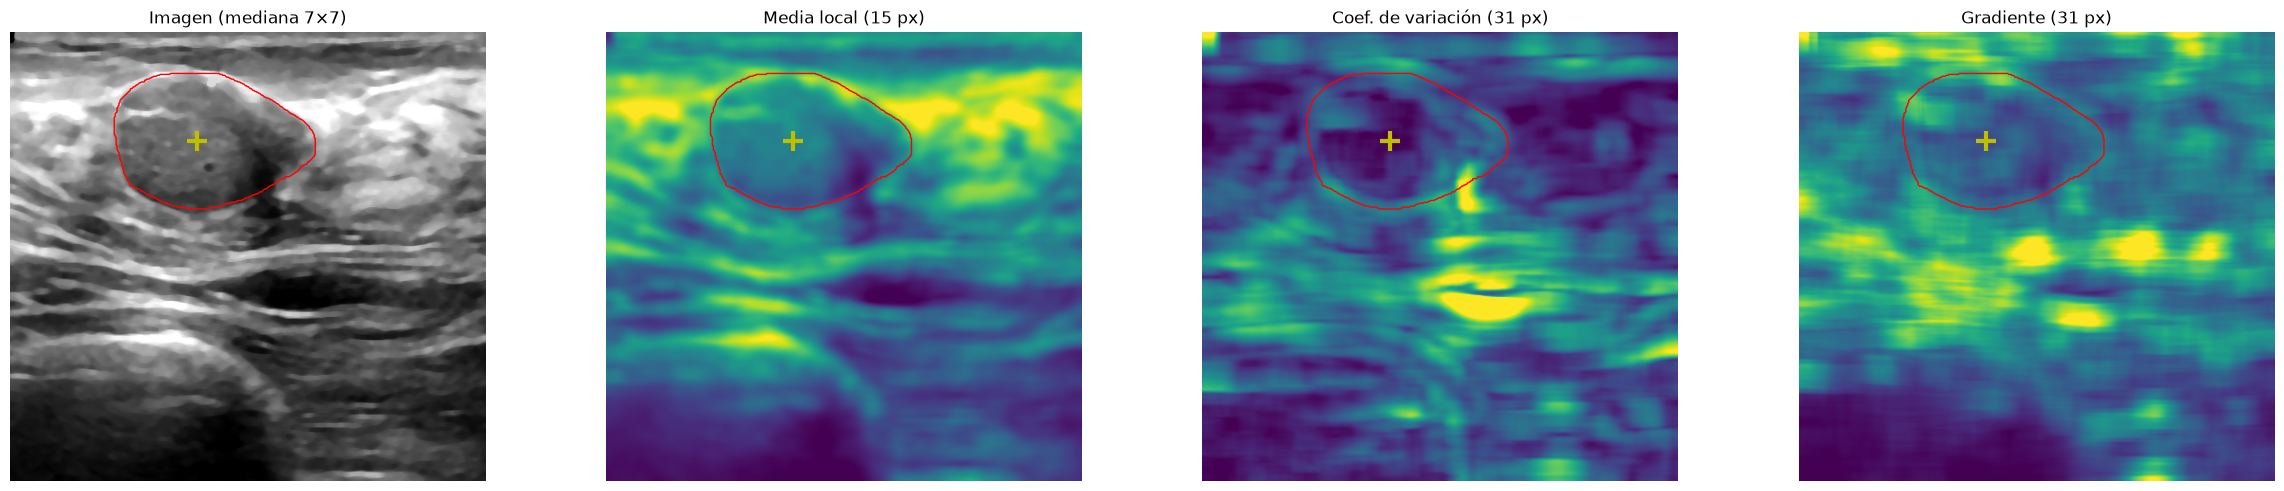

In [4]:
EJEMPLO = "benign (436)"          # el mismo ejemplo de las Partes 3 y 4
img, mascara, marcas = cargar_limpio(casos.loc[EJEMPLO])
semilla = segmentacion.semilla_desde_mascara(mascara)
gt = segmentacion.lesion_principal(mascara)
mapas_ej = segmentacion.mapas_segmentacion(img)

titulos = {"imagen": "Imagen (mediana 7×7)", "media": "Media local (15 px)",
           "cv": "Coef. de variación (31 px)", "gradiente": "Gradiente (31 px)"}
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
for ax, (nombre, titulo) in zip(axes, titulos.items()):
    m = mapas_ej[nombre]
    lim = np.percentile(m, [1, 99])
    ax.imshow(m, cmap="gray" if nombre == "imagen" else "viridis", vmin=lim[0], vmax=lim[1])
    ax.contour(gt, levels=[0.5], colors="red", linewidths=1)
    ax.plot(semilla[1], semilla[0], "y+", markersize=14, markeredgewidth=3)
    ax.set_title(titulo)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Qué vemos:** igual que en la Parte 4, la lesión es una zona **oscura** en la imagen y en la media local, y tiene **σ/μ alto** (el desvío relativo al brillo crece en lo oscuro) y **poco gradiente**. Pero ninguno de los mapas tiene un borde neto: la media local también es baja en las zonas oscuras de abajo, y los mapas de 31 px son manchas que "desbordan" el contorno de la lesión.

### 2.1 Los métodos

**Crecimiento de regiones** (`segmentacion.region_growing`). Empieza con la semilla y va agregando vecinos (vecindad de 8) mientras su valor esté a menos de una **tolerancia** de la **media actual de la región**. Se recorre en anchura (BFS) con una cola: primero los vecinos de la semilla, después los vecinos de esos, etc. La media se actualiza con cada píxel que entra, así que la región se "adapta" al nivel de gris de la lesión. El único parámetro es la tolerancia: si es chica la región se queda corta; si es grande, **se escapa** al tejido por cualquier zona del borde donde el contraste sea bajo (el borde difuso de las malignas, por ejemplo).

**k-means** (`segmentacion.kmeans_mapas`). Cada píxel es un punto con una coordenada por mapa: (media, σ/μ, gradiente). k-means agrupa los puntos en *k* grupos (*clusters*) alrededor de *k* centros, alternando dos pasos: asignar cada píxel al centro más cercano y mover cada centro al promedio de sus píxeles. Antes, cada mapa se **estandariza** (media 0, desvío 1) para que todos pesen igual. La lesión es el **cluster que contiene la semilla**. Parámetro: *k*.

**Chan-Vese** (`skimage.segmentation.chan_vese`). Un contorno activo que divide la imagen en dos regiones (adentro y afuera de una curva) buscando que cada una sea lo más **uniforme** posible alrededor de su media, con un costo `mu` por el **largo** del contorno (mu alto = contorno más liso). A diferencia de los contornos que buscan bordes, no necesita un borde nítido: separa por diferencia de medias, justo lo que la media local distingue mejor. Arranca en un círculo alrededor de la semilla.

**Otsu**. Elige automáticamente el umbral que mejor divide el histograma de la media local en dos grupos. La lesión es el grupo de la semilla. No tiene parámetros: es la referencia "más simple posible" contra la que comparar.

**Zona de trabajo.** Todos los métodos se pueden aplicar a la imagen entera o a una **ventana cuadrada fija** de `lado` px centrada en la semilla. La ventana limita cuánto puede escaparse el region growing y hace que k-means, Otsu y Chan-Vese "vean" sobre todo la lesión y su entorno, y no zonas oscuras lejanas (sombras, fondo). El lado se elige con los datos (sección 4), es igual para todas las imágenes y no usa la máscara.

**Refinamiento** (`segmentacion.refinar`, igual para todos): **apertura** con un disco de radio 3 (borra puentes finos por los que la región se escapó y puntitos sueltos), **cierre** (tapa grietas del borde), **relleno de huecos** (los quistes tienen puntos brillantes adentro) y nos quedamos con la **componente conexa que contiene la semilla**.

Así se ve cada método en el ejemplo, con parámetros "razonables" (todavía sin ajustar), antes y después del refinamiento:

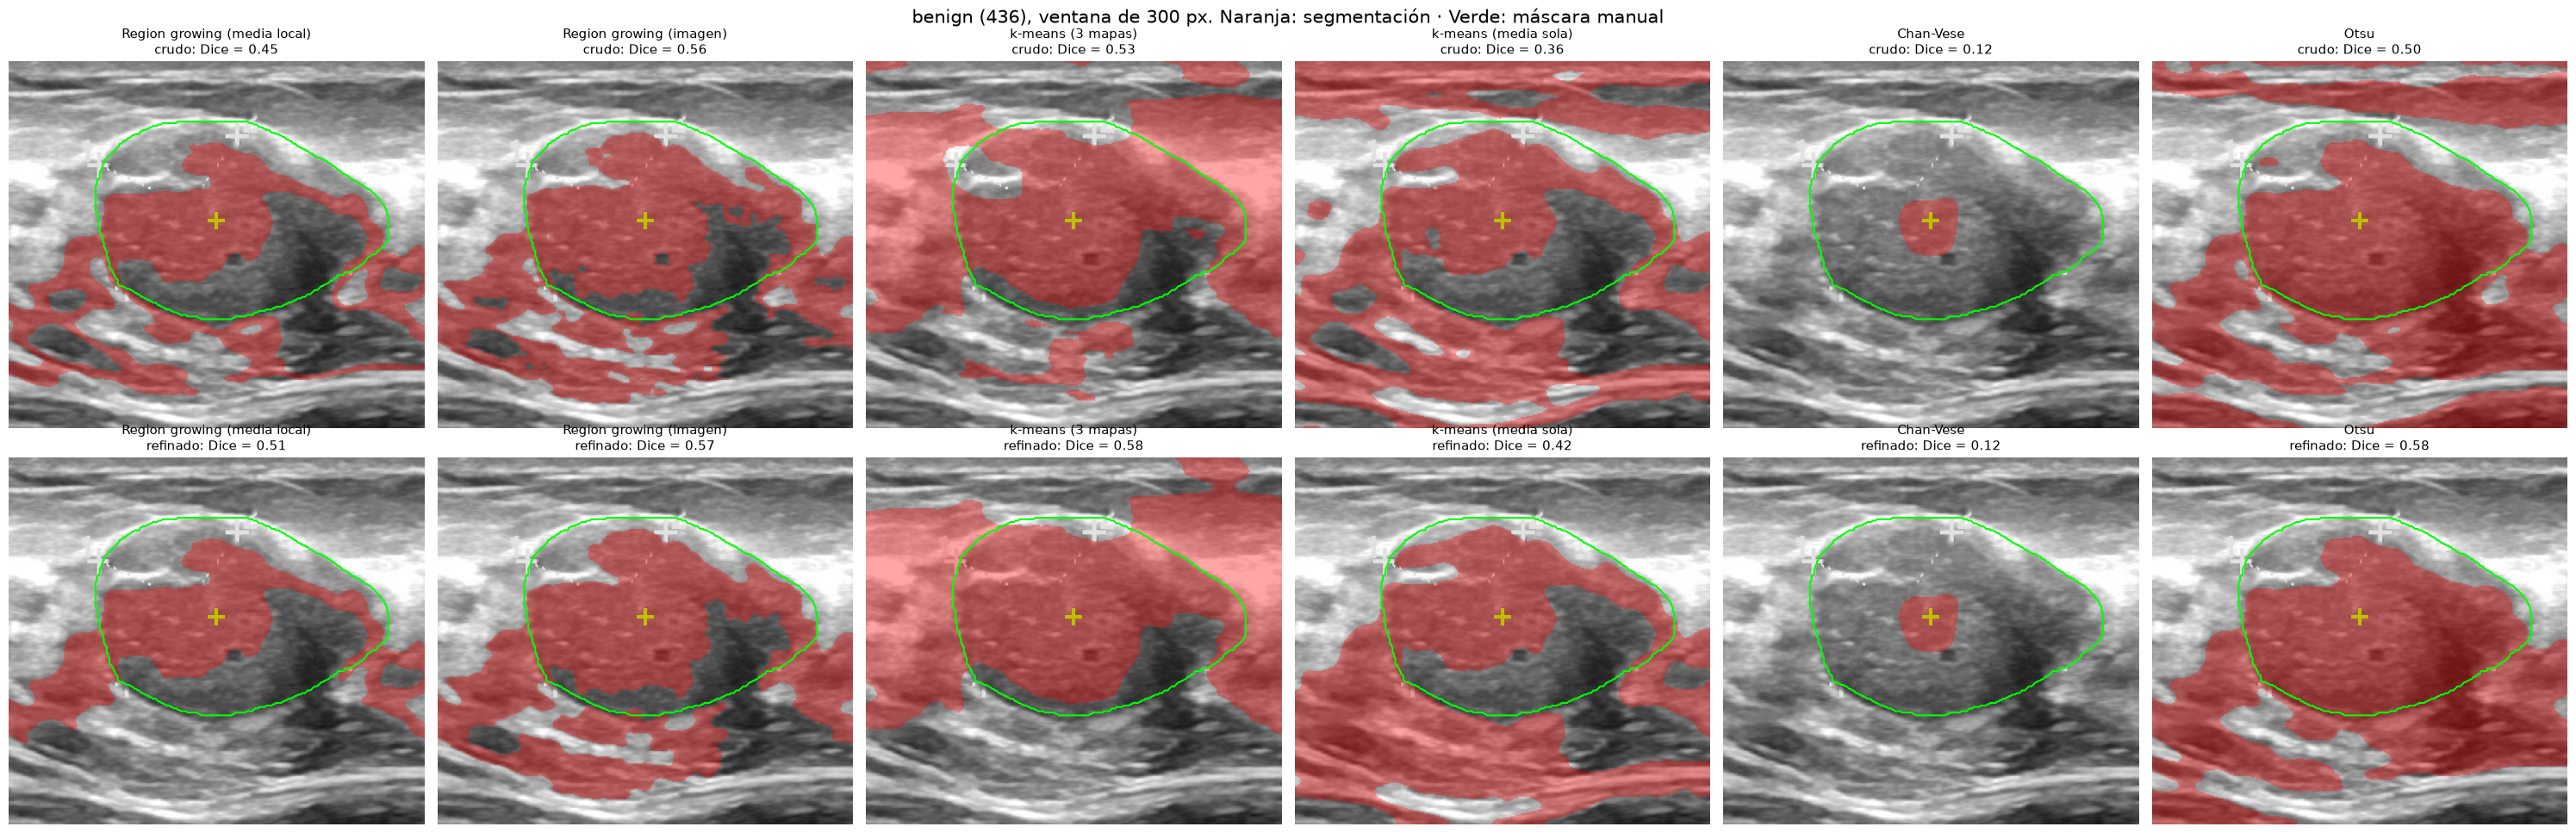

In [5]:
from skimage import segmentation as sk_seg

PRUEBA = {"rg_media": {"tolerancia": 15}, "rg_imagen": {"tolerancia": 30}, "kmeans_3mapas": {"k": 3},
          "kmeans_media": {"k": 3}, "chan_vese": {"mu": 0.05}, "otsu": {}}
zona = segmentacion.zona_trabajo(img.shape, semilla, 300)
s = (semilla[0] - zona[0].start, semilla[1] - zona[1].start)

fig, axes = plt.subplots(2, 6, figsize=(30, 10))
for j, (metodo, params) in enumerate(PRUEBA.items()):
    # crudo: sin refinar, para ver qué hace el refinamiento
    rec = {k: v[zona] for k, v in mapas_ej.items()}
    if metodo.startswith("rg"):
        cruda = segmentacion.region_growing(rec["media" if metodo == "rg_media" else "imagen"], s, params["tolerancia"])
    elif metodo.startswith("kmeans"):
        lista = [rec["media"], rec["cv"], rec["gradiente"]] if metodo == "kmeans_3mapas" else [rec["media"]]
        et = segmentacion.kmeans_mapas(lista, params["k"])
        cruda = et == et[s]
    elif metodo == "chan_vese":
        cruda = segmentacion.chan_vese(rec["media"], s, mu=params["mu"])
    else:
        cruda = segmentacion.otsu(rec["media"], s)
    refinada = segmentacion.refinar(cruda, s)
    for i, (m, nombre) in enumerate([(cruda, "crudo"), (refinada, "refinado")]):
        ax = axes[i, j]
        ax.imshow(img[zona], cmap="gray", vmin=0, vmax=255)
        ax.imshow(np.ma.masked_where(~m, m), cmap="autumn", alpha=0.35)
        ax.contour(gt[zona], levels=[0.5], colors="lime", linewidths=1.5)
        ax.plot(s[1], s[0], "y+", markersize=14, markeredgewidth=3)
        ax.set_title(f"{NOMBRES[metodo]}\n{nombre}: Dice = {segmentacion.dice(m, gt[zona]):.2f}", fontsize=11)
        ax.axis("off")
fig.suptitle(f"{EJEMPLO}, ventana de 300 px. Naranja: segmentación · Verde: máscara manual", fontsize=15)
plt.tight_layout()
plt.show()

**Qué vemos:**
- **Ningún método encuentra exactamente la lesión**, ni siquiera en esta imagen "fácil" de las Partes 3 y 4. El problema común: alrededor de la lesión hay tejido **tan oscuro como ella** (abajo y a la derecha), y los métodos que agrupan por brillo lo juntan con la lesión.
- **Region growing** (las dos versiones) no se escapa demasiado, pero se queda corto: el borde derecho de la lesión es más oscuro que su centro y queda afuera con esta tolerancia.
- **k-means** y **Otsu** marcan como "lesión" todo lo oscuro de la ventana; el refinamiento (quedarse con la componente de la semilla) recorta parte, pero lo que está pegado a la lesión queda.
- **Chan-Vese** con mu = 0,05 se quedó en un círculo chico alrededor de la semilla: el contorno no creció. Muestra que el resultado depende mucho de mu y de la ventana; por eso los parámetros se eligen con datos en la sección siguiente.
- El **refinamiento** mejora un poco a casi todos (de 0,45 a 0,51 en region growing; de 0,53 a 0,58 en k-means): borra puntitos sueltos y rellena huecos.

## 3. Cómo medimos: Dice e IoU

Comparamos la segmentación $A$ con la lesión de referencia $B$:

$$\text{Dice} = \frac{2\,|A \cap B|}{|A| + |B|} \qquad\qquad \text{IoU} = \frac{|A \cap B|}{|A \cup B|}$$

Los dos valen 1 si coinciden exactamente y 0 si no se tocan. Están relacionados ($\text{IoU} = \text{Dice} / (2 - \text{Dice})$), así que **ordenan los métodos igual**; el IoU es siempre más bajo (un Dice de 0,8 es un IoU de 0,67). Reportamos los dos porque en la literatura se usan los dos.

Una referencia para interpretar los números: entre dos radiólogos que dibujan la misma lesión, el Dice suele estar entre 0,8 y 0,9. Un Dice < 0,2 es, en la práctica, un **fallo** (la región se escapó o quedó en un rincón de la lesión).

## 4. Elección de parámetros en un subconjunto de ajuste

Cada método tiene parámetros (tolerancia, *k*, mu, lado de la ventana). Si los eligiéramos mirando el Dice en las 647 imágenes y después reportáramos ese mismo Dice, el resultado estaría **inflado**: habríamos elegido justo lo que mejor anda en esas imágenes (**sobreajuste**). Por eso separamos:
- un **subconjunto de ajuste** (30 % de las imágenes, estratificado por clase) donde probamos todas las combinaciones y elegimos la mejor de cada método (la de mayor Dice medio);
- un **subconjunto de evaluación** (el 70 % restante) donde medimos el resultado con los parámetros ya fijos. Es el resultado que reportamos.

Grilla de parámetros:

| Método | Parámetro | Valores |
|---|---|---|
| Todos | lado de la ventana | 150, 200, 300, 400 px y la imagen entera |
| Region growing (media local) | tolerancia (niveles de gris) | 5, 10, 15, 20, 25, 30, 35, 40, 50 |
| Region growing (imagen) | tolerancia | 10, 20, 30, 40, 50 (la imagen tiene más grano que la media local: necesita más tolerancia) |
| k-means (3 mapas y media sola) | *k* | 2, 3, 4 |
| Chan-Vese | mu | 0,01, 0,05, 0,1 (solo con ventanas: sobre la imagen entera tarda ~10 s por imagen y configuración) |
| Otsu | — | — |

El radio del refinamiento queda fijo en 3 px para todos. Son 117 combinaciones por imagen; se calculan en paralelo (`joblib`, un proceso por núcleo) y el resultado se guarda en `outputs/segmentacion/`.

In [6]:
ajuste_ids, evaluacion_ids = train_test_split(list(con_lesion.index), test_size=0.7, stratify=list(con_lesion["clase"]),
                                              random_state=SEED)
ajuste_ids, evaluacion_ids = sorted(ajuste_ids), sorted(evaluacion_ids)
print(f"Ajuste: {len(ajuste_ids)} imágenes ({(con_lesion.loc[ajuste_ids, 'clase'] == 'malignant').sum()} malignas)")
print(f"Evaluación: {len(evaluacion_ids)} imágenes ({(con_lesion.loc[evaluacion_ids, 'clase'] == 'malignant').sum()} malignas)")

LADOS = [150, 200, 300, 400, 0]     # 0 = imagen entera
GRILLA = ([{"metodo": "rg_media", "tolerancia": t} for t in (5, 10, 15, 20, 25, 30, 35, 40, 50)]
          + [{"metodo": "rg_imagen", "tolerancia": t} for t in (10, 20, 30, 40, 50)]
          + [{"metodo": m, "k": k} for m in ("kmeans_3mapas", "kmeans_media") for k in (2, 3, 4)]
          + [{"metodo": "chan_vese", "mu": mu} for mu in (0.01, 0.05, 0.1)]
          + [{"metodo": "otsu"}])
# Chan-Vese solo con ventanas: sobre la imagen entera tarda ~10 s por imagen y configuración
CONFIGS = [dict(c, lado=lado) for c in GRILLA for lado in LADOS
           if not (c["metodo"] == "chan_vese" and lado == 0)]
print(f"{len(CONFIGS)} combinaciones por imagen")

def medir(id_caso, configs, devolver_mascaras=False):
    # Segmenta una imagen con todas las configuraciones (se ejecuta en paralelo, una imagen por proceso).
    import warnings
    from threadpoolctl import threadpool_limits
    warnings.filterwarnings("ignore")
    img, mascara, _ = cargar_limpio(casos.loc[id_caso])
    with threadpool_limits(1):        # un hilo por proceso: si no, k-means usa todos los núcleos en cada proceso
        resultado = segmentacion.evaluar_caso(img, mascara, configs, devolver_mascaras)
    filas = resultado[0] if devolver_mascaras else resultado
    for f in filas:
        f.update(id=id_caso, clase=casos.loc[id_caso, "clase"])
    return resultado

Ajuste: 194 imágenes (63 malignas)
Evaluación: 453 imágenes (147 malignas)
117 combinaciones por imagen


In [7]:
RECALCULAR = False
archivo_ajuste = CARPETA / "ajuste.csv"
parcial = archivo_ajuste.with_name("ajuste_parcial.csv")    # se guarda cada 50 imágenes: si se corta, retoma
if archivo_ajuste.exists() and not RECALCULAR:
    ajuste = pd.read_csv(archivo_ajuste)
    print("Resultados leídos de", archivo_ajuste)
else:
    filas = pd.read_csv(parcial).to_dict("records") if parcial.exists() and not RECALCULAR else []
    hechas = {f["id"] for f in filas}
    pendientes = [i for i in ajuste_ids if i not in hechas]
    for inicio in range(0, len(pendientes), 50):
        bloque = pendientes[inicio:inicio + 50]
        for resultado in Parallel(n_jobs=-1)(delayed(medir)(i, CONFIGS) for i in bloque):
            filas.extend(resultado)
        pd.DataFrame(filas).to_csv(parcial, index=False)
        print(f"{len(hechas) + inicio + len(bloque)} de {len(ajuste_ids)} imágenes")
    ajuste = pd.DataFrame(filas)
    ajuste.to_csv(archivo_ajuste, index=False)
    parcial.unlink(missing_ok=True)
ajuste["lado"] = ajuste["lado"].astype(int)
ajuste["parametro"] = ajuste[["tolerancia", "k", "mu"]].bfill(axis=1).iloc[:, 0]
print(f"{ajuste['id'].nunique()} imágenes, {len(ajuste)} segmentaciones")

Resultados leídos de /Users/luciaburman/PSIB_TPI_GRUPO_13/outputs/segmentacion/ajuste.csv
194 imágenes, 22698 segmentaciones


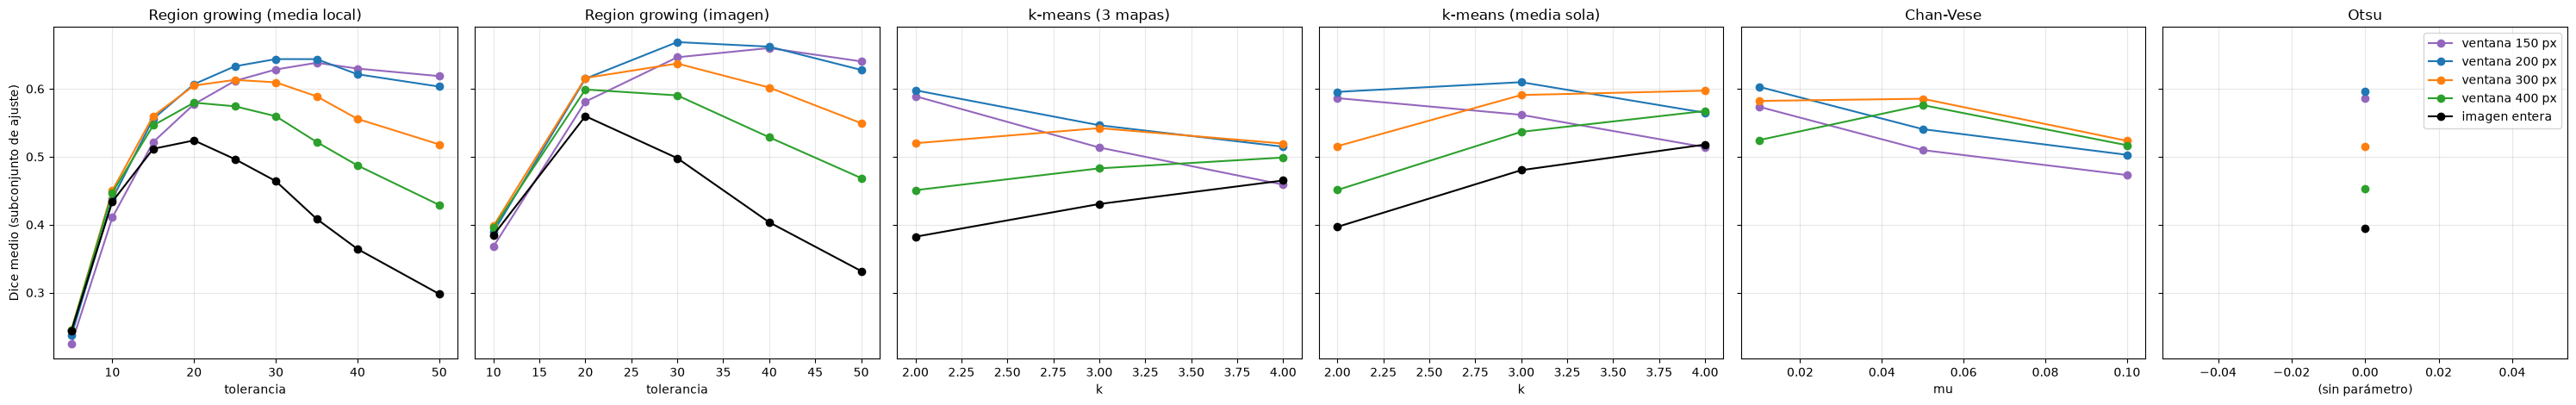

,parámetro,ventana,Dice medio (ajuste),Dice mediano (ajuste)
método,,,,
Region growing (media local),tolerancia = 30,200 px,0.644,0.695
Region growing (imagen),tolerancia = 30,200 px,0.669,0.701
k-means (3 mapas),k = 2,200 px,0.598,0.622
k-means (media sola),k = 3,200 px,0.610,0.631
Chan-Vese,mu = 0.01,200 px,0.603,0.663
Otsu,—,200 px,0.596,0.627


In [8]:
resumen_ajuste = (ajuste.groupby(["metodo", "parametro", "lado"], dropna=False)["dice"].mean()
                  .reset_index())
fig, axes = plt.subplots(1, 6, figsize=(30, 4.8), sharey=True)
for ax, metodo in zip(axes, NOMBRES):
    datos = resumen_ajuste[resumen_ajuste["metodo"] == metodo]
    for lado, color in zip(LADOS, ["tab:purple", "tab:blue", "tab:orange", "tab:green", "black"]):
        d = datos[datos["lado"] == lado]
        x = d["parametro"] if metodo != "otsu" else [0]
        ax.plot(x, d["dice"], "o-", color=color, label="imagen entera" if lado == 0 else f"ventana {lado} px")
    ax.set_title(NOMBRES[metodo])
    ax.set_xlabel({"rg_media": "tolerancia", "rg_imagen": "tolerancia", "kmeans_3mapas": "k",
                   "kmeans_media": "k", "chan_vese": "mu", "otsu": "(sin parámetro)"}[metodo])
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Dice medio (subconjunto de ajuste)")
axes[-1].legend()
plt.tight_layout()
plt.show()

idx = ajuste.groupby(["metodo", "parametro", "lado"], dropna=False)["dice"].mean().groupby("metodo").idxmax()
MEJORES = {}
filas = []
for metodo in NOMBRES:
    _, parametro, lado = idx[metodo]
    config = {"metodo": metodo, "lado": int(lado)}
    nombre_param = {"rg_media": "tolerancia", "rg_imagen": "tolerancia", "kmeans_3mapas": "k",
                    "kmeans_media": "k", "chan_vese": "mu"}.get(metodo)
    if nombre_param:
        config[nombre_param] = int(parametro) if nombre_param != "mu" else float(parametro)
    MEJORES[metodo] = config
    d = ajuste[(ajuste["metodo"] == metodo) & (ajuste["lado"] == lado)
               & ((ajuste["parametro"] == parametro) | pd.isna(parametro))]
    filas.append({"método": NOMBRES[metodo], "parámetro": f"{nombre_param} = {config[nombre_param]}" if nombre_param else "—",
                  "ventana": "imagen entera" if lado == 0 else f"{int(lado)} px",
                  "Dice medio (ajuste)": d["dice"].mean(), "Dice mediano (ajuste)": d["dice"].median()})
pd.DataFrame(filas).set_index("método").round(3)

**Qué vemos:**
- **La ventana importa más que el parámetro de cada método.** Con la imagen entera (negro) todos los métodos empeoran mucho: k-means y Otsu juntan con la lesión cualquier zona oscura conectada (sombras, el fondo de la imagen), y el region growing con tolerancia alta se escapa por toda la imagen. **La mejor ventana es la de 200 px en los seis métodos.** Con 150 px empeoran todos: la ventana empieza a cortar las lesiones grandes.
- **Region growing:** el Dice sube con la tolerancia hasta ~30 niveles de gris y después baja (la región se escapa). Sobre la media local, 30 y 35 empatan (0,644); sobre la imagen gana 30 (0,669). Con tolerancias bajas (5–10) la región casi no crece: el *speckle* dentro de la lesión ya supera esa tolerancia.
- **k-means:** con 3 mapas gana k = 2; con la media sola, k = 3 (un grupo para lo muy oscuro, otro para el tejido intermedio y otro para lo brillante).
- **Chan-Vese:** gana el mu más chico (0,01). Es el extremo de la grilla, pero la diferencia con 0,05 en la ventana de 300 px es mínima (0,603 contra 0,585): no esperamos una mejora grande con valores más chicos.
- Los cinco mejores están cerca entre sí (Dice medio 0,60–0,67 en el ajuste). **Los dos crecimientos de regiones van primero.**

Al principio la grilla llegaba hasta tolerancia 30 y ventana de 200 px, y los mejores valores caían justo en ese **borde**: no se podía saber si más allá seguía mejorando. Por eso la ampliamos (tolerancias 35–50, ventana de 150 px). Ahora el óptimo queda adentro de la grilla.

## 5. Evaluación en el resto de las imágenes

Con los parámetros elegidos, segmentamos **las 647 imágenes** (las guardamos para la Parte 6, que calcula los descriptores sobre nuestra segmentación) y medimos Dice e IoU. Los resultados que reportamos son los del **subconjunto de evaluación** (453 imágenes que no se usaron para elegir nada); al final mostramos también las 647 como referencia.

In [9]:
archivo_eval = CARPETA / "evaluacion.csv"
if archivo_eval.exists() and not RECALCULAR:
    res = pd.read_csv(archivo_eval)
    print("Resultados leídos de", archivo_eval)
else:
    configs = list(MEJORES.values())
    salida = Parallel(n_jobs=-1)(delayed(medir)(i, configs, True) for i in con_lesion.index)
    res = pd.DataFrame([f for filas, _ in salida for f in filas])
    res.to_csv(archivo_eval, index=False)
    # máscaras de cada método, para la Parte 6
    for j, metodo in enumerate(MEJORES):
        np.savez_compressed(CARPETA / f"mascaras_{metodo}.npz",
                            **{i: mascaras[j] for i, (_, mascaras) in zip(con_lesion.index, salida)})
res["subconjunto"] = np.where(res["id"].isin(ajuste_ids), "ajuste", "evaluación")
ev = res[res["subconjunto"] == "evaluación"]
print(f"{res['id'].nunique()} imágenes; evaluación: {ev['id'].nunique()}")

Resultados leídos de /Users/luciaburman/PSIB_TPI_GRUPO_13/outputs/segmentacion/evaluacion.csv
647 imágenes; evaluación: 453


## 6. Resultados

### 6.1 ¿Qué método segmenta mejor?

Para cada método, en el subconjunto de evaluación: Dice e IoU medios y medianos, el porcentaje de imágenes con Dice ≥ 0,8 (una segmentación comparable a la de otro radiólogo) y el de **fallos** (Dice < 0,2).

In [10]:
def tabla_metodos(df):
    t = df.groupby("metodo").agg(
        dice_medio=("dice", "mean"), dice_mediano=("dice", "median"),
        iou_medio=("iou", "mean"), iou_mediano=("iou", "median"),
        dice_mayor_08=("dice", lambda s: 100 * (s >= 0.8).mean()),
        fallos=("dice", lambda s: 100 * (s < 0.2).mean()))
    t = t.sort_values("dice_medio", ascending=False)
    t.index = [NOMBRES[m] for m in t.index]
    return t.rename(columns={"dice_medio": "Dice medio", "dice_mediano": "Dice mediano", "iou_medio": "IoU medio",
                             "iou_mediano": "IoU mediano", "dice_mayor_08": "% Dice ≥ 0,8", "fallos": "% fallos (Dice < 0,2)"})

tabla_metodos(ev).round(3)

,Dice medio,Dice mediano,IoU medio,IoU mediano,"% Dice ≥ 0,8","% fallos (Dice < 0,2)"
Region growing (imagen),0.654,0.683,0.513,0.518,25.166,2.208
Region growing (media local),0.638,0.670,0.491,0.504,18.102,2.428
Chan-Vese,0.601,0.646,0.466,0.477,22.075,5.519
k-means (media sola),0.593,0.612,0.455,0.441,20.751,3.974
Otsu,0.582,0.610,0.445,0.439,17.439,5.960
k-means (3 mapas),0.568,0.580,0.432,0.409,18.322,6.181


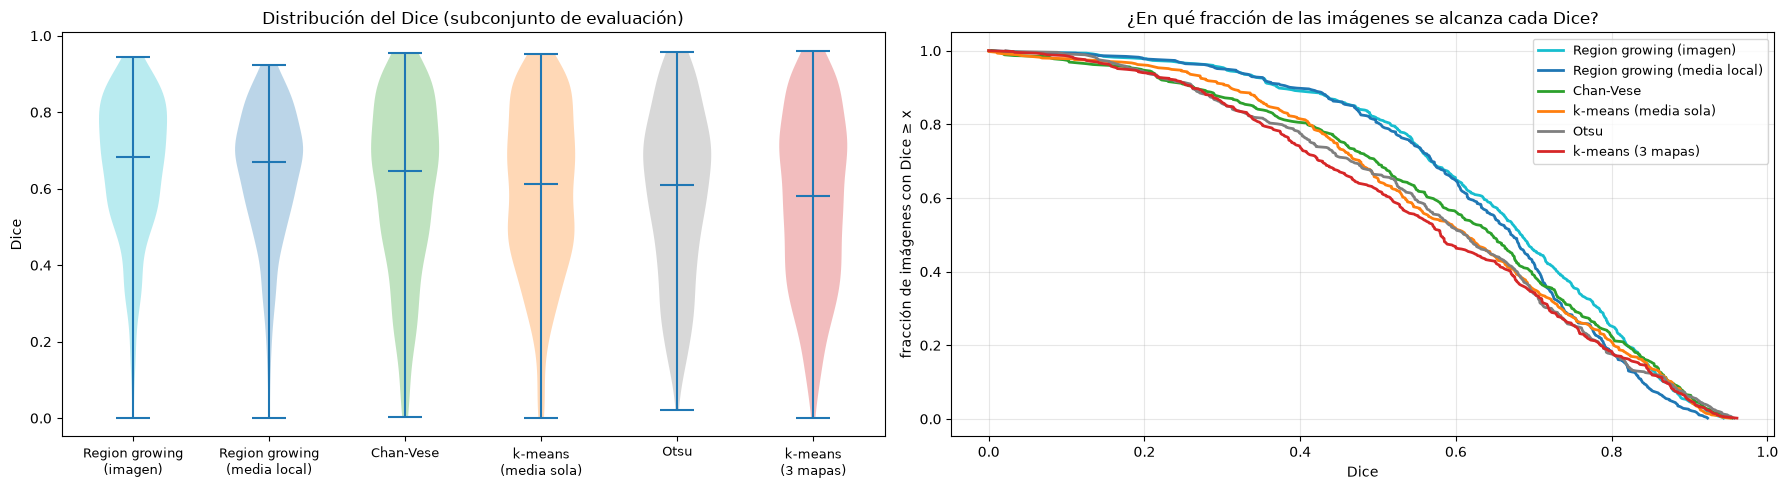

In [11]:
orden = ev.groupby("metodo")["dice"].mean().sort_values(ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
datos = [ev.loc[ev["metodo"] == m, "dice"] for m in orden]
partes = axes[0].violinplot(datos, showmedians=True)
for cuerpo, m in zip(partes["bodies"], orden):
    cuerpo.set_facecolor(COLORES[m])
axes[0].set_xticks(range(1, len(orden) + 1))
axes[0].set_xticklabels([NOMBRES[m].replace(" (", "\n(") for m in orden], fontsize=9)
axes[0].set_ylabel("Dice")
axes[0].set_title("Distribución del Dice (subconjunto de evaluación)")
for m in orden:
    d = np.sort(ev.loc[ev["metodo"] == m, "dice"])
    axes[1].plot(d, 1 - np.arange(len(d)) / len(d), color=COLORES[m], label=NOMBRES[m], linewidth=2)
axes[1].set_xlabel("Dice")
axes[1].set_ylabel("fracción de imágenes con Dice ≥ x")
axes[1].set_title("¿En qué fracción de las imágenes se alcanza cada Dice?")
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Qué vemos:**
- **El mejor método es el crecimiento de regiones sobre la imagen** (mediana 7 × 7, tolerancia 30, ventana de 200 px): **Dice medio 0,654** (mediana 0,683) e **IoU medio 0,513** en las 453 imágenes de evaluación. Le sigue el crecimiento de regiones sobre la media local (0,638), después Chan-Vese (0,601), k-means con la media sola (0,593), Otsu (0,582) y k-means con los 3 mapas (0,568).
- **Casi no hubo sobreajuste:** el Dice en evaluación es apenas menor que en el ajuste (0,654 contra 0,669 para el mejor; ver sección 6.8). Con pocos parámetros por método y 194 imágenes de ajuste, la elección es estable.
- Solo el **25 %** de las imágenes alcanza un Dice ≥ 0,8 con el mejor método: la mayoría de las segmentaciones están "en la zona" de la lesión pero con un contorno bastante distinto del manual. Los **fallos** (Dice < 0,2) son pocos: 2 % en los crecimientos de regiones, 4–6 % en los demás.
- La distribución (violines) es ancha en todos: el mismo método da Dice > 0,9 en unas imágenes y < 0,3 en otras. Lo que más pesa es **cómo es la imagen**, no el método.

Para dar una idea de la escala: los trabajos de *deep learning* sobre BUSI (U-Net y variantes) reportan Dice medios de alrededor de 0,7–0,8, aprendiendo de cientos de imágenes con máscara. Nuestro método no aprende nada de las máscaras salvo cuatro parámetros, y parte de un clic.

### 6.2 Benignas y malignas

La Parte 4 anticipó que las malignas iban a ser más difíciles (su lesión separa peor del tejido: AUC 0,80 contra 0,92 en la media local). Dice medio por clase y prueba U de Mann-Whitney (imágenes independientes):

In [12]:
filas = []
for m in orden:
    b = ev.loc[(ev["metodo"] == m) & (ev["clase"] == "benign"), "dice"]
    ma = ev.loc[(ev["metodo"] == m) & (ev["clase"] == "malignant"), "dice"]
    filas.append({"método": NOMBRES[m], "Dice medio benignas": b.mean(), "Dice medio malignas": ma.mean(),
                  "Dice mediano benignas": b.median(), "Dice mediano malignas": ma.median(),
                  "% fallos benignas": 100 * (b < 0.2).mean(), "% fallos malignas": 100 * (ma < 0.2).mean(),
                  "p (Mann-Whitney)": f"{mannwhitneyu(b, ma).pvalue:.1e}"})
pd.DataFrame(filas).set_index("método").round(3)

,Dice medio benignas,Dice medio malignas,Dice mediano benignas,Dice mediano malignas,% fallos benignas,% fallos malignas,p (Mann-Whitney)
método,,,,,,,
Region growing (imagen),0.674,0.612,0.726,0.619,2.288,2.041,1.0e-06
Region growing (media local),0.648,0.615,0.695,0.615,3.268,0.680,5.2e-04
Chan-Vese,0.623,0.556,0.677,0.578,5.229,6.122,1.2e-04
k-means (media sola),0.621,0.535,0.663,0.535,4.248,3.401,4.0e-06
Otsu,0.573,0.600,0.612,0.609,8.170,1.361,6.7e-01
k-means (3 mapas),0.563,0.579,0.585,0.573,8.824,0.680,8.9e-01


**Qué vemos:**
- Con los **crecimientos de regiones, Chan-Vese y k-means con la media**, las **malignas se segmentan peor** (por ejemplo, el mejor método: Dice medio 0,612 contra 0,674; Mann-Whitney p < 0,001), como anticipó la Parte 4: su borde es difuso y el contraste con el tejido es menor, así que la región se escapa o se corta antes.
- **Otsu y k-means con 3 mapas no muestran diferencia entre clases** (p = 0,67 y 0,89), pero no porque segmenten bien las malignas sino porque segmentan **peor las benignas** (0,57 y 0,56). Las benignas suelen ser más chicas (Parte 0), y estos dos métodos fallan justamente en las lesiones chicas (sección 6.6).
- Los fallos (Dice < 0,2) son, curiosamente, **más frecuentes en las benignas** en 5 de los 6 métodos (por ejemplo, 8–9 % contra ~1 % con Otsu y k-means de 3 mapas). Como vemos en los ejemplos (sección 6.7), los fallos graves vienen de lesiones chicas o con el interior heterogéneo, más que del borde difuso.

### 6.3 Comparación entre métodos: Wilcoxon pareado

Todos los métodos segmentan **las mismas imágenes**, así que los comparamos **imagen por imagen** con la prueba de rangos con signo de Wilcoxon (pareada), como en las Partes 3 y 4. En cada casilla: el porcentaje de imágenes en que el método de la fila tiene **mayor** Dice que el de la columna, y el p-valor. Son 15 comparaciones: con la corrección de Bonferroni, el umbral de significación pasa de 0,05 a 0,05 / 15 ≈ 0,003.

In [13]:
pivote = ev.pivot(index="id", columns="metodo", values="dice")[list(orden)]
gana = pd.DataFrame(index=[NOMBRES[m] for m in orden], columns=[NOMBRES[m] for m in orden], dtype=object)
for a in orden:
    for b in orden:
        if a == b:
            gana.loc[NOMBRES[a], NOMBRES[b]] = "—"
            continue
        p = wilcoxon(pivote[a], pivote[b]).pvalue
        gana.loc[NOMBRES[a], NOMBRES[b]] = f"{100 * (pivote[a] > pivote[b]).mean():.0f} % (p = {p:.0e})"
gana

,Region growing (imagen),Region growing (media local),Chan-Vese,k-means (media sola),Otsu,k-means (3 mapas)
Region growing (imagen),—,67 % (p = 6e-14),56 % (p = 5e-06),64 % (p = 3e-16),56 % (p = 1e-06),60 % (p = 8e-12)
Region growing (media local),33 % (p = 6e-14),—,47 % (p = 8e-02),56 % (p = 3e-07),52 % (p = 2e-03),53 % (p = 4e-07)
Chan-Vese,44 % (p = 5e-06),53 % (p = 8e-02),—,62 % (p = 3e-05),47 % (p = 7e-01),49 % (p = 3e-01)
k-means (media sola),36 % (p = 3e-16),44 % (p = 3e-07),38 % (p = 3e-05),—,42 % (p = 5e-02),46 % (p = 7e-01)
Otsu,44 % (p = 1e-06),48 % (p = 2e-03),53 % (p = 7e-01),58 % (p = 5e-02),—,51 % (p = 4e-02)
k-means (3 mapas),40 % (p = 8e-12),47 % (p = 4e-07),51 % (p = 3e-01),54 % (p = 7e-01),49 % (p = 4e-02),—


**Qué vemos:**
- **El crecimiento de regiones sobre la imagen es mejor que todos los demás** (p ≤ 10⁻⁶ en las 5 comparaciones, por debajo del umbral de Bonferroni de 0,003). Le gana al segundo, el crecimiento sobre la media local, en el 67 % de las imágenes.
- El **crecimiento sobre la media local** le gana a k-means con la media (p = 3·10⁻⁷), a k-means con 3 mapas (p = 4·10⁻⁷) y a Otsu (p = 0,002). Contra **Chan-Vese** no hay diferencia significativa (p = 0,08).
- **Chan-Vese, Otsu y k-means con 3 mapas no se distinguen entre sí** (p ≥ 0,3). Chan-Vese le gana a k-means con la media en el 62 % de las imágenes (p = 3·10⁻⁵).
- k-means con la media sola y con los 3 mapas **no se distinguen** en el total (p = 0,7): lo miramos en detalle en la sección siguiente.

### 6.4 ¿La textura suma algo al brillo?

Es la pregunta que dejó abierta la Parte 4: cada AUC miraba un mapa por vez, así que no sabíamos si **combinar** la textura (σ/μ y gradiente) con el brillo mejora la segmentación. Comparamos k-means con los tres mapas contra k-means con la media local sola, **cada uno con sus mejores parámetros**, imagen por imagen y por clase (en la Parte 4, la textura pesaba relativamente más en las malignas).

In [14]:
filas = []
for clase, nombre in [(None, "todas"), ("benign", "benignas"), ("malignant", "malignas")]:
    d = pivote if clase is None else pivote[con_lesion.loc[pivote.index, "clase"] == clase]
    dif = d["kmeans_3mapas"] - d["kmeans_media"]
    filas.append({"imágenes": nombre, "n": len(d),
                  "Dice medio 3 mapas": d["kmeans_3mapas"].mean(), "Dice medio media sola": d["kmeans_media"].mean(),
                  "diferencia mediana": dif.median(),
                  "% imágenes mejor con 3 mapas": 100 * (dif > 0).mean(),
                  "p (Wilcoxon)": f"{wilcoxon(d['kmeans_3mapas'], d['kmeans_media']).pvalue:.1e}"})
pd.DataFrame(filas).set_index("imágenes").round(3)

,n,Dice medio 3 mapas,Dice medio media sola,diferencia mediana,% imágenes mejor con 3 mapas,p (Wilcoxon)
imágenes,,,,,,
todas,453,0.568,0.593,0.011,53.642,7.4e-01
benignas,306,0.563,0.621,-0.006,47.059,2.0e-02
malignas,147,0.579,0.535,0.051,67.347,1.9e-05


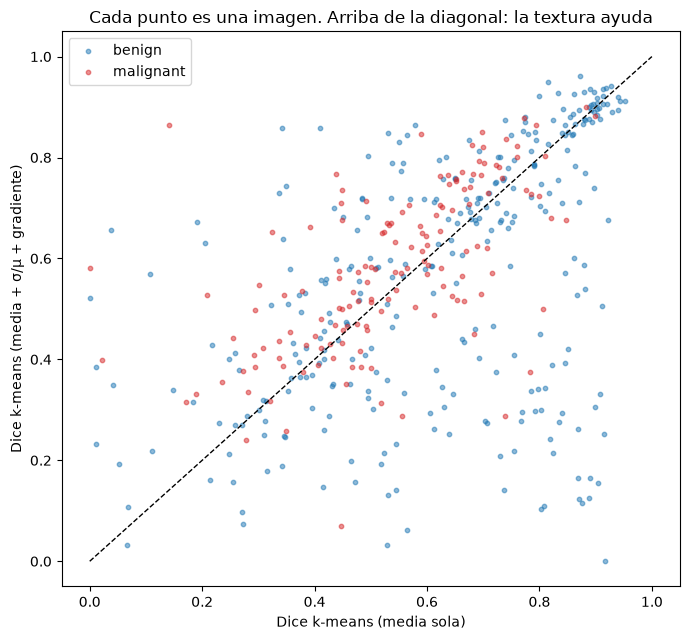

In [15]:
fig, ax = plt.subplots(figsize=(7, 6.5))
for clase, color in [("benign", "tab:blue"), ("malignant", "tab:red")]:
    d = pivote[con_lesion.loc[pivote.index, "clase"] == clase]
    ax.scatter(d["kmeans_media"], d["kmeans_3mapas"], s=10, alpha=0.5, color=color, label=clase)
ax.plot([0, 1], [0, 1], "k--", linewidth=1)
ax.set_xlabel("Dice k-means (media sola)")
ax.set_ylabel("Dice k-means (media + σ/μ + gradiente)")
ax.set_title("Cada punto es una imagen. Arriba de la diagonal: la textura ayuda")
ax.legend()
plt.tight_layout()
plt.show()

**Qué vemos:** **sumar la textura no mejora la segmentación en general, pero el efecto depende de la clase**, y en sentidos opuestos:
- En el **total**, empatan (Dice medio 0,568 con 3 mapas contra 0,593 con la media sola; p = 0,74).
- En las **benignas**, la textura **empeora** levemente (0,563 contra 0,621; p = 0,02).
- En las **malignas**, la textura **mejora**: 0,579 contra 0,535, mejor en el 67 % de las imágenes (p = 2·10⁻⁵, significativo incluso con la corrección de Bonferroni).

Es lo que anticipaba la Parte 4: en las malignas el brillo separa peor la lesión del tejido (AUC 0,80 contra 0,92) y la textura pesa relativamente más. En las benignas, que tienen buen contraste de brillo, los mapas de textura de 31 px agregan sobre todo borde borroso. En el gráfico se ve: los puntos rojos (malignas) quedan mayormente arriba de la diagonal.

**Respuesta a la pregunta abierta de la Parte 4:** la textura **sí aporta información** que el brillo no tiene, pero solo en las lesiones donde el brillo no alcanza (las malignas). Como método general, combinarla con k-means no compensa: el mejor método usa solo el brillo.

### 6.5 ¿Segmentar sobre la imagen o sobre el mapa?

El anteproyecto propone comparar la segmentación sobre la imagen original y sobre los mapas. Lo hacemos con el crecimiento de regiones, que es el método más sensible al ruido: sobre la imagen (mediana 7 × 7) cada píxel decide por sí solo; sobre la media local decide el promedio de su vecindad.

In [16]:
filas = []
for clase, nombre in [(None, "todas"), ("benign", "benignas"), ("malignant", "malignas")]:
    d = pivote if clase is None else pivote[con_lesion.loc[pivote.index, "clase"] == clase]
    filas.append({"imágenes": nombre, "Dice medio imagen": d["rg_imagen"].mean(), "Dice medio media local": d["rg_media"].mean(),
                  "% imágenes mejor con la media local": 100 * (d["rg_media"] > d["rg_imagen"]).mean(),
                  "p (Wilcoxon)": f"{wilcoxon(d['rg_media'], d['rg_imagen']).pvalue:.1e}"})
pd.DataFrame(filas).set_index("imágenes").round(3)

,Dice medio imagen,Dice medio media local,% imágenes mejor con la media local,p (Wilcoxon)
imágenes,,,,
todas,0.654,0.638,32.892,6.2e-14
benignas,0.674,0.648,25.490,6.3e-16
malignas,0.612,0.615,48.299,7.2e-01


**Qué vemos:** un resultado que **no esperábamos**: el crecimiento de regiones funciona **mejor sobre la imagen** (mediana 7 × 7) que sobre la media local (0,654 contra 0,638, p = 6·10⁻¹⁴), aunque la media local era el mapa que mejor separaba en la Parte 4 (AUC 0,88 contra 0,86).

La diferencia está **toda en las benignas** (0,674 contra 0,648; la imagen gana en el 75 % de ellas); en las malignas empatan (p = 0,72). Nuestra interpretación: la media local promedia en 15 px y **corre el borde** de la lesión hacia afuera o hacia adentro (mezcla lesión y tejido en una franja de ~7 px de cada lado). El AUC de la Parte 4 no lo veía, porque comparaba el interior de la lesión con un anillo que empieza 5 px afuera del borde. El crecimiento sobre la imagen se detiene en el borde real, y la mediana 7 × 7 ya alcanza para que el *speckle* no lo frene antes. En las benignas, que tienen borde neto, eso se nota; en las malignas, con borde difuso, no hay un borde neto que preservar.

Es la misma limitación que la Parte 4 anotó para su propia medida: **separar bien el interior no es lo mismo que ubicar bien el borde**, y el Dice depende sobre todo del borde.

### 6.6 ¿Importa el tamaño de la lesión?

La Parte 4 advirtió que las ventanas de 31 px del σ/μ y del gradiente podrían deformar el contorno en lesiones chicas: una ventana más grande que la lesión mezcla lesión y tejido en todos lados. Dividimos las imágenes de evaluación en tres grupos de igual tamaño según el área de la lesión (terciles) y miramos el Dice de cada método.

In [17]:
area = ev.drop_duplicates("id").set_index("id")["area_gt"]
terciles = pd.qcut(area, 3, labels=["chicas", "medianas", "grandes"])
limites = area.groupby(terciles, observed=True).agg(["min", "max"])
print("Área de la lesión (px) en cada tercil:")
print(limites, "\n")
ev = ev.assign(tamano=ev["id"].map(terciles))
tabla_tam = ev.pivot_table(index="metodo", columns="tamano", values="dice", aggfunc="mean", observed=True).loc[orden]
tabla_tam.index = [NOMBRES[m] for m in tabla_tam.index]
tabla_tam.round(3)

Área de la lesión (px) en cada tercil:
            min     max
area_gt                
chicas      804    9048
medianas   9108   30588
grandes   30669  191793 



tamano,chicas,medianas,grandes
Region growing (imagen),0.662,0.675,0.624
Region growing (media local),0.609,0.675,0.629
Chan-Vese,0.614,0.687,0.502
k-means (media sola),0.651,0.645,0.484
Otsu,0.465,0.684,0.597
k-means (3 mapas),0.471,0.679,0.555


**Qué vemos:**
- **Lesiones chicas** (menos de ~9000 px, unos 100 px de diámetro): **Otsu y k-means con 3 mapas fallan** (Dice 0,47), mientras que k-means con la media sola llega a 0,65 y el crecimiento sobre la imagen a 0,66. Es la respuesta a la otra pregunta de la Parte 4: **las ventanas de 31 px sí deforman el contorno de las lesiones chicas**. Una lesión de 60 px de ancho queda "borroneada" en el σ/μ y el gradiente, y k-means con esos mapas la mezcla con su entorno. Otsu falla en las chicas por otro motivo: en una ventana de 200 px la lesión es una parte mínima y el umbral queda en la zona del tejido.
- **Lesiones medianas:** todos los métodos andan parecido (0,65–0,69).
- **Lesiones grandes** (más de ~30 000 px): caen Chan-Vese (0,50) y k-means (0,48–0,56). Es el costo de la **ventana de 200 px**: el 32 % de las lesiones ocupa más que un círculo de 200 px de diámetro, así que la ventana las corta (en los ejemplos de la sección 6.7 se ven bordes rectos). Los crecimientos de regiones sufren menos (0,62–0,63) porque, dentro de la ventana, igual se detienen en el borde.

Elegir una sola ventana para todas las imágenes es un compromiso: una más grande ayudaría a las lesiones grandes pero deja escapar la región en las chicas (sección 4). Una mejora natural sería una ventana que crezca mientras la región toque su borde.

### 6.7 Ejemplos buenos y malos

Para el mejor método, las segmentaciones con Dice más alto, cercano a la mediana y más bajo del subconjunto de evaluación. En verde la máscara manual, en naranja nuestra segmentación, en amarillo la semilla.

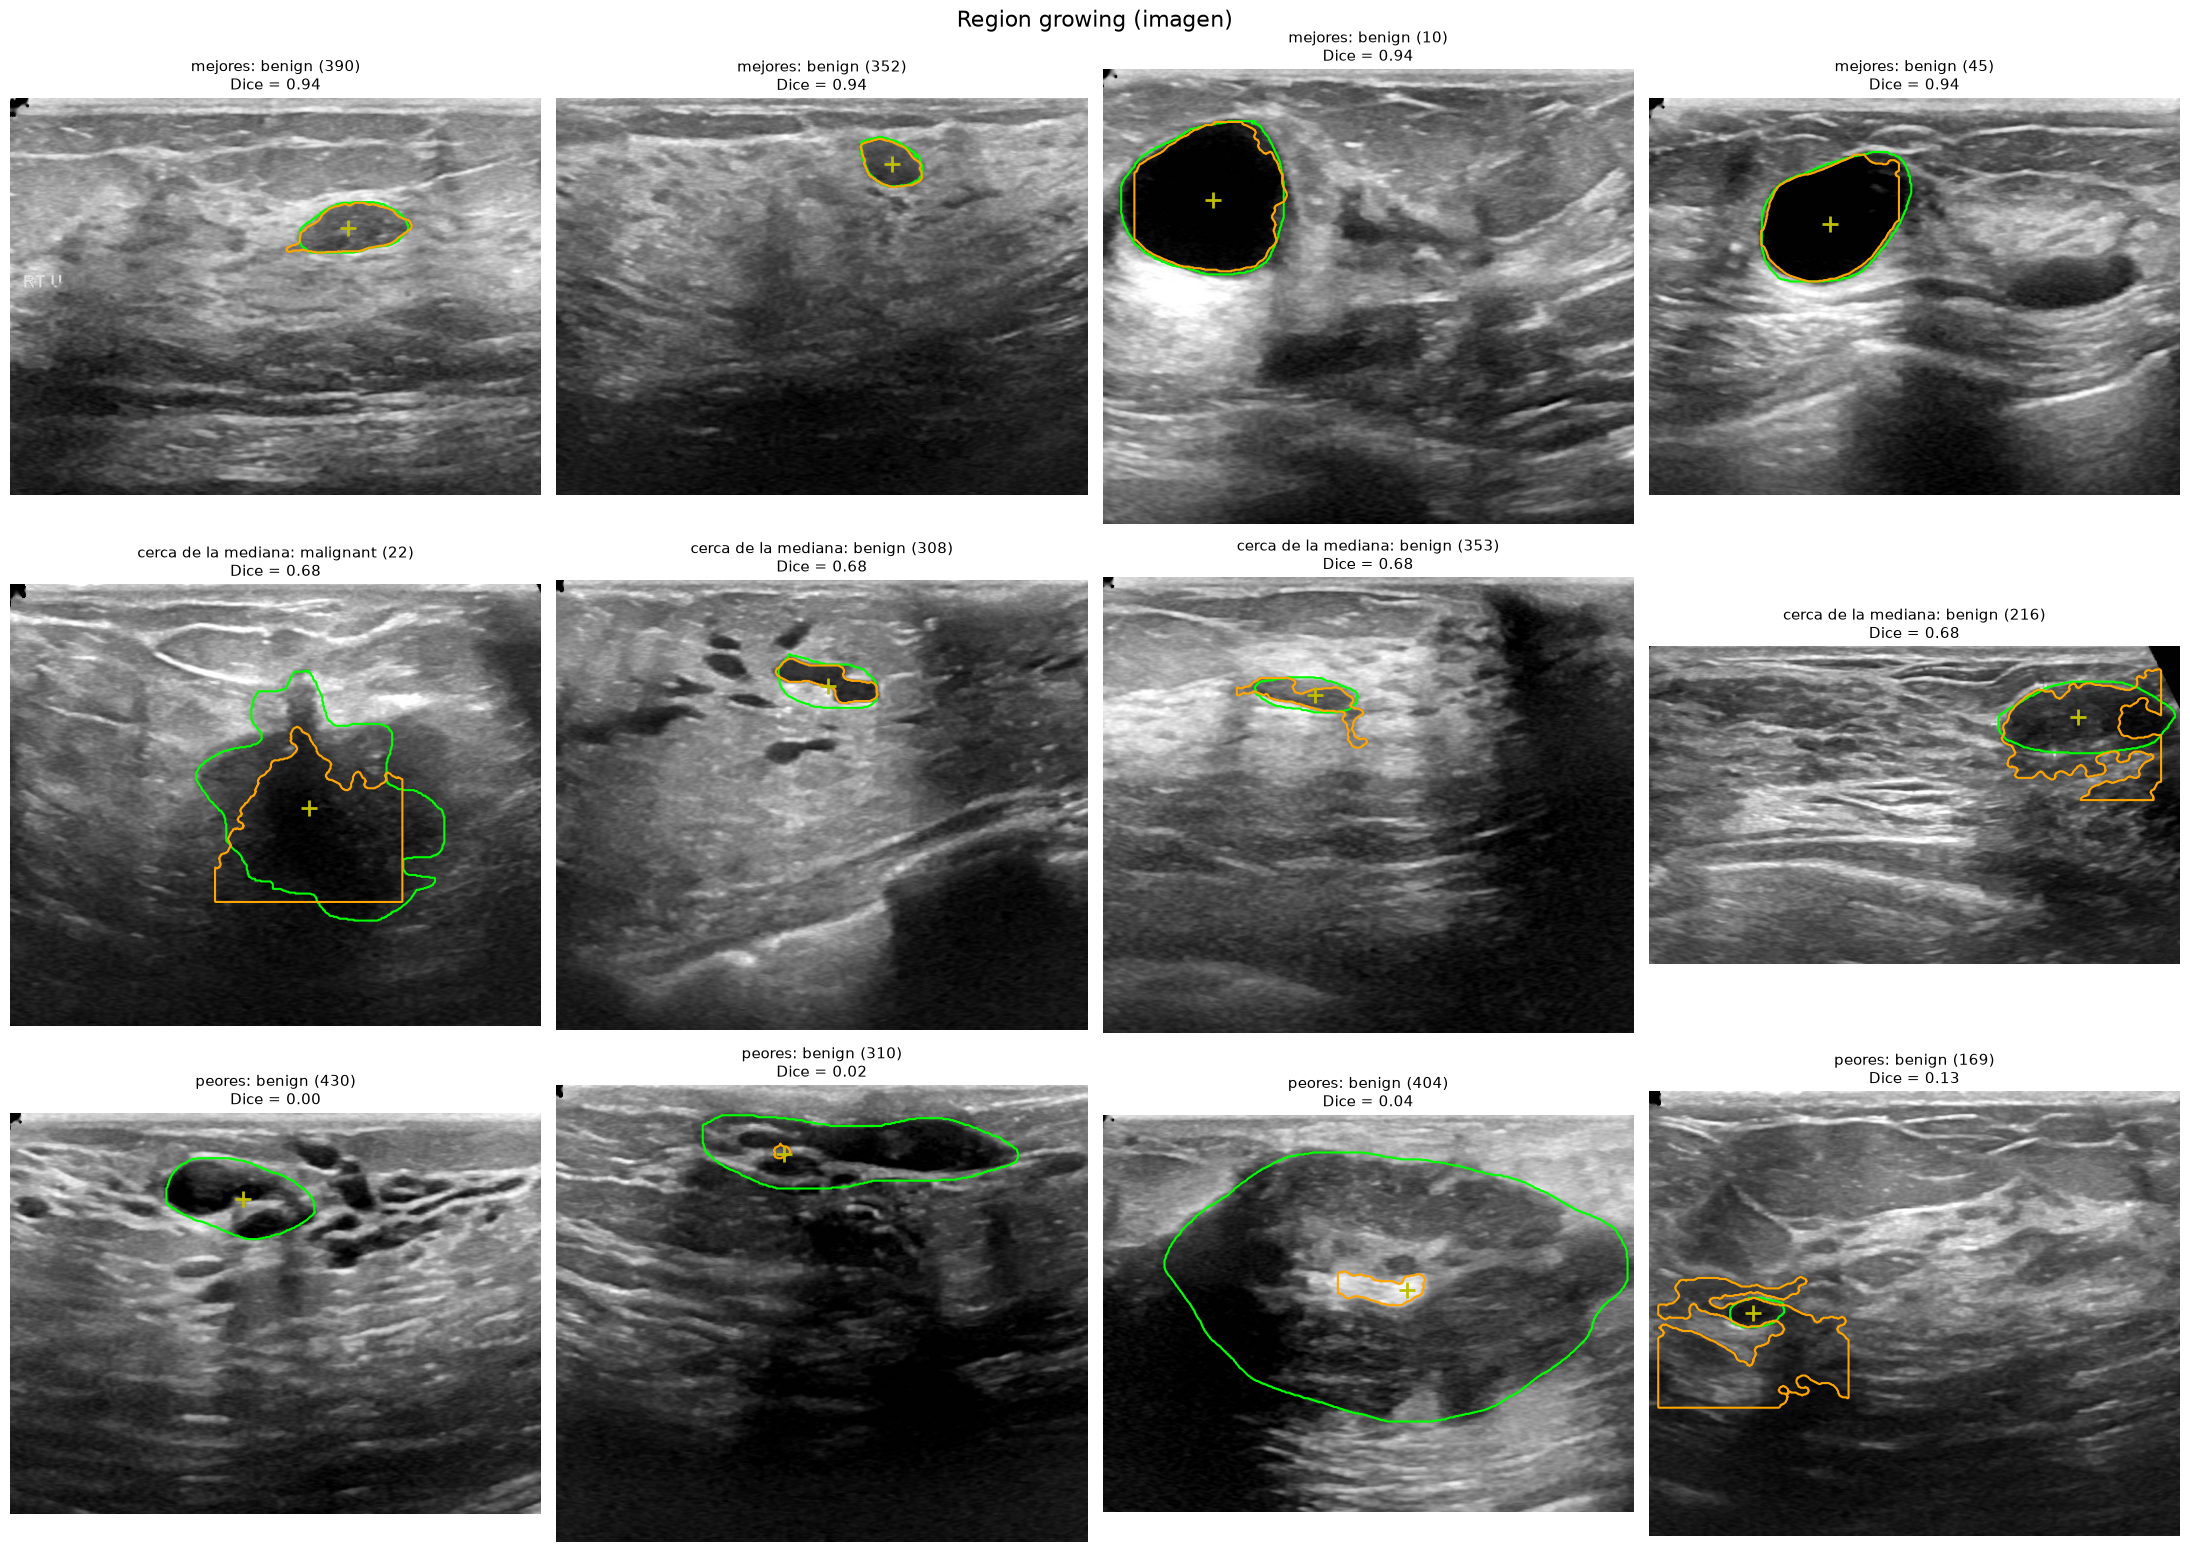

In [18]:
MEJOR = orden[0]
mascaras_mejor = np.load(CARPETA / f"mascaras_{MEJOR}.npz")
d = ev[ev["metodo"] == MEJOR].sort_values("dice")
elegidos = {"mejores": d.tail(4)["id"].tolist()[::-1],
            "cerca de la mediana": d.iloc[len(d) // 2 - 2: len(d) // 2 + 2]["id"].tolist(),
            "peores": d.head(4)["id"].tolist()}

fig, axes = plt.subplots(3, 4, figsize=(22, 16))
for fila, (grupo, ids) in zip(axes, elegidos.items()):
    for ax, id_caso in zip(fila, ids):
        img, mascara, _ = cargar_limpio(casos.loc[id_caso])
        pred = mascaras_mejor[id_caso]
        gt = segmentacion.lesion_principal(mascara)
        s = segmentacion.semilla_desde_mascara(mascara)
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.contour(gt, levels=[0.5], colors="lime", linewidths=1.5)
        if pred.any():
            ax.contour(pred, levels=[0.5], colors="orange", linewidths=1.5)
        ax.plot(s[1], s[0], "y+", markersize=12, markeredgewidth=2)
        ax.set_title(f"{grupo}: {id_caso}\nDice = {segmentacion.dice(pred, gt):.2f}", fontsize=11)
        ax.axis("off")
fig.suptitle(f"{NOMBRES[MEJOR]}", fontsize=16)
plt.tight_layout()
plt.show()

**Qué vemos:**
- **Los mejores** (Dice 0,94) son **quistes** o nódulos muy oscuros (anecoicos) con borde neto: la lesión es casi uniforme y el tejido alrededor es claro, así que el crecimiento se detiene justo en el borde.
- **Cerca de la mediana** (Dice 0,68) aparecen los dos problemas típicos: la región se **escapa** hacia tejido oscuro pegado a la lesión (`benign (216)`, `benign (353)`) o queda **cortada en línea recta** por la ventana de 200 px (`malignant (22)`, `benign (216)`). En `malignant (22)` además falta la parte superior de la lesión, que es más clara que su centro.
- **Los peores** tienen una causa común que no es el método sino **la semilla**: el punto más interior de la máscara cae sobre un píxel mucho **más claro** que la lesión (un tabique o eco interno). En `benign (430)` la semilla vale 76 y la mediana de la lesión 54; en `benign (310)`, 73 contra 41; en `benign (404)`, 250 contra 68. Desde ahí la región crece por los ecos internos claros y no por la lesión, o queda tan chica que el refinamiento la borra (`benign (430)`: segmentación vacía). En `benign (169)` (una lesión chica) la región se escapa al tejido de alrededor.

Un usuario real haría clic en una zona **representativa** de la lesión, no en el centro geométrico. Así que una parte de los fallos viene de cómo simulamos el clic, no del método.

### 6.8 Todas las imágenes (referencia)

Las mismas medidas sobre las 647 imágenes (ajuste + evaluación). No es el resultado "limpio", porque incluye las imágenes con las que se eligieron los parámetros, pero permite comparar con trabajos que reportan sobre todo el dataset.

In [19]:
t_ajuste = res[res["subconjunto"] == "ajuste"].groupby("metodo")["dice"].mean()
t = tabla_metodos(res)
t["Dice medio en ajuste"] = [t_ajuste[m] for m in orden]
t["Dice medio en evaluación"] = [ev.loc[ev["metodo"] == m, "dice"].mean() for m in orden]
t.round(3)

,Dice medio,Dice mediano,IoU medio,IoU mediano,"% Dice ≥ 0,8","% fallos (Dice < 0,2)",Dice medio en ajuste,Dice medio en evaluación
Region growing (imagen),0.658,0.691,0.517,0.528,25.657,2.164,0.669,0.654
Region growing (media local),0.639,0.676,0.493,0.511,18.083,2.473,0.644,0.638
Chan-Vese,0.602,0.649,0.466,0.480,21.638,5.564,0.603,0.601
k-means (media sola),0.598,0.619,0.459,0.448,21.329,3.709,0.610,0.593
Otsu,0.586,0.615,0.448,0.444,17.311,5.564,0.596,0.582
k-means (3 mapas),0.577,0.586,0.441,0.414,18.856,5.564,0.598,0.568


**Qué vemos:** sobre las 647 imágenes, los números cambian muy poco (el mejor método pasa de 0,654 a 0,658) y el orden de los métodos es el mismo. La diferencia entre ajuste y evaluación es de 0,01–0,03 en todos los métodos: separar los subconjuntos casi no cambia el resultado, pero era necesario para poder afirmarlo.

## 7. Conclusiones

Segmentamos las 647 lesiones de BUSI a partir de un clic simulado, con seis métodos vistos en clase. Los parámetros se eligieron en 194 imágenes y el resultado se midió en las 453 restantes, contra la lesión que contiene la semilla.

| Pregunta | Respuesta | Evidencia |
|---|---|---|
| ¿Qué método segmenta mejor? | **Crecimiento de regiones sobre la mediana 7 × 7** (tolerancia 30, ventana de 200 px): **Dice 0,654** (mediana 0,683), **IoU 0,513** | Sección 6.1; Wilcoxon contra los otros cinco, p ≤ 10⁻⁶ (6.3) |
| ¿Y los demás? | Crecimiento sobre la media local 0,638; Chan-Vese 0,601; k-means (media) 0,593; Otsu 0,582; k-means (3 mapas) 0,568 | Sección 6.1 |
| ¿Hubo sobreajuste al elegir parámetros? | Casi nada: el Dice de evaluación es 0,01–0,03 menor que el de ajuste | Secciones 6.1 y 6.8 |
| ¿Qué parámetro importa más? | La **ventana de trabajo**: sin ventana los métodos caen a Dice 0,40–0,56 (Chan-Vese no se probó sin ventana). La mejor es 200 px en todos | Sección 4 |
| ¿Benignas y malignas? | Las **malignas se segmentan peor** con los mejores métodos (0,61 contra 0,67, p = 10⁻⁶) | Sección 6.2 |
| ¿La textura suma algo al brillo? | **Solo en las malignas**: k-means con textura mejora 0,535 → 0,579 (p = 2·10⁻⁵) pero empeora las benignas. En total, empate | Sección 6.4 |
| ¿Imagen o mapa? | Sobre la **imagen** (mediana 7 × 7) es mejor que sobre la media local (p = 6·10⁻¹⁴): la media local corre el borde. Contradice lo que sugería el AUC de la Parte 4 | Sección 6.5 |
| ¿Las ventanas de 31 px deforman el contorno? | **Sí, en las lesiones chicas**: k-means con 3 mapas cae a 0,47 contra 0,65 con la media sola | Sección 6.6 |
| ¿De dónde vienen los fallos? | Semillas sobre ecos internos claros, regiones que se escapan a tejido oscuro vecino y lesiones grandes cortadas por la ventana | Secciones 6.6 y 6.7 |

**Para la Parte 6:** usamos las máscaras del **crecimiento de regiones sobre la imagen**, guardadas en `outputs/segmentacion/mascaras_rg_imagen.npz`, para comparar los descriptores calculados con nuestra segmentación contra los de la máscara manual.

**Limitaciones:**
1. **La semilla simulada** es el punto más interior de la máscara manual. No es un clic real: en lesiones heterogéneas cae a veces sobre un eco interno claro (sección 6.7), y un usuario elegiría mejor. En el otro sentido, un usuario real podría hacer clic más cerca del borde. No medimos la sensibilidad a la posición de la semilla.
2. **Un solo tamaño de ventana** para todas las imágenes: corta el 32 % de las lesiones (las más grandes que un círculo de 200 px). Una ventana adaptativa (que crezca mientras la región toque su borde) probablemente mejoraría las lesiones grandes.
3. **La referencia es una sola máscara manual**, que tampoco es exacta (las Partes 3 y 4 ya lo notaron). Ningún método puede tener Dice 1 contra una referencia imperfecta.
4. **El subconjunto de ajuste se eligió al azar sin tener en cuenta las imágenes casi duplicadas** (Parte 6). Una imagen de evaluación puede tener su casi-gemela en el ajuste. Con solo cuatro parámetros por método, el efecto debería ser chico: la diferencia entre ajuste y evaluación ya lo es.
5. Chan-Vese quedó con el mu más chico de la grilla (0,01) y se probó solo con ventanas, por tiempo de cálculo (~10 s por imagen con la imagen entera).
6. Las distancias están en píxeles: no conocemos los mm por píxel de cada imagen, así que la misma ventana abarca distinta cantidad de tejido en imágenes distintas.